Imports & Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import os

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Move up to project root (from notebooks/ to root)
os.chdir("..")

# 2. Add root to path 
sys.path.append(str(Path.cwd()))
from src.data.loader import load_raw
from src.features.build_features import build_features

Load and Prepare Data

In [3]:
# Load raw data and feature engineering
df = load_raw()
df = build_features(df)

df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

print(f"Dataset shape: {df.shape}")
print(f"Overall 30-day readmission rate: {df['readmitted_30d'].mean():.2%}")

Dataset shape: (101766, 63)
Overall 30-day readmission rate: 11.16%


Target Distribution (Class Imbalance)

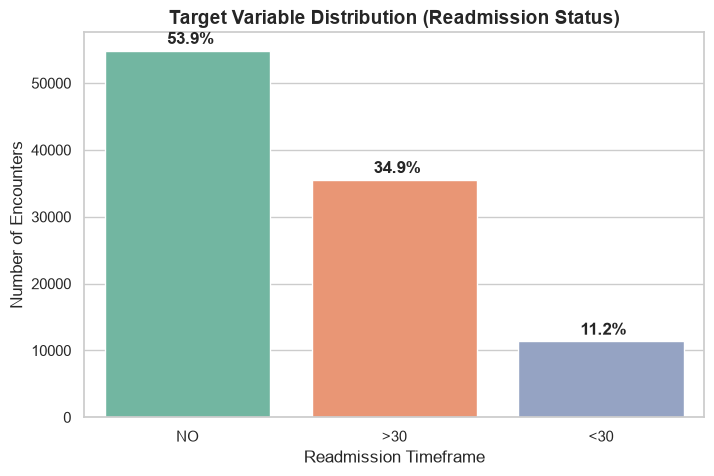

In [9]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], hue="readmitted", palette="Set2", legend=False)
plt.title("Target Variable Distribution (Readmission Status)", fontsize=14, fontweight="bold")
plt.xlabel("Readmission Timeframe")
plt.ylabel("Number of Encounters")

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 1000
    ax.annotate(percentage, (x, y), size=12, fontweight="bold")

plt.show()

Length of Stay vs Readmission

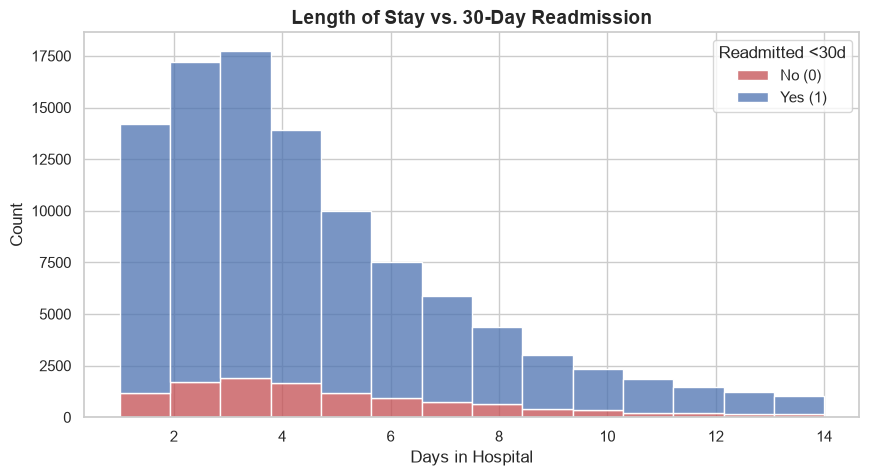

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="time_in_hospital", hue="readmitted_30d", 
             multiple="stack", bins=14, palette={0: "#4C72B0", 1: "#C44E52"})
plt.title("Length of Stay vs. 30-Day Readmission", fontsize=14, fontweight="bold")
plt.xlabel("Days in Hospital")
plt.ylabel("Count")
plt.legend(title="Readmitted <30d", labels=["No (0)", "Yes (1)"])
plt.show()

Demographics (Age & Race)

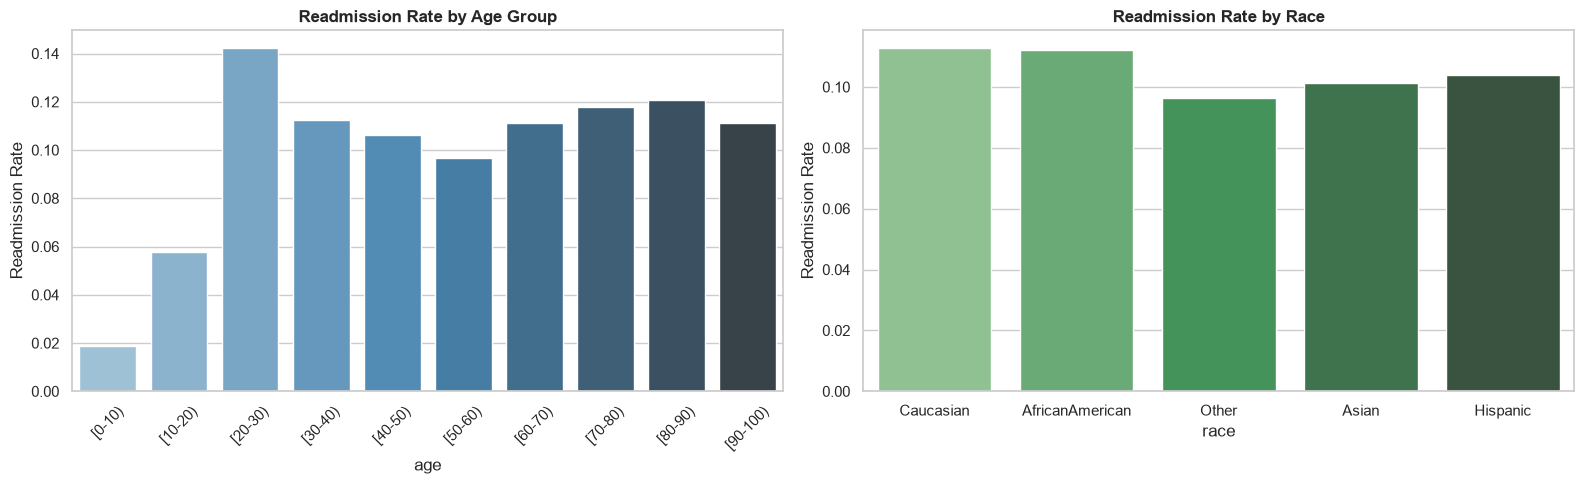

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df, x="age", y="readmitted_30d", ax=axes[0], errorbar=None, hue="age", palette="Blues_d", legend=False)
axes[0].set_title("Readmission Rate by Age Group", fontweight="bold")
axes[0].set_ylabel("Readmission Rate")
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=df, x="race", y="readmitted_30d", ax=axes[1], errorbar=None, hue="race", palette="Greens_d", legend=False)
axes[1].set_title("Readmission Rate by Race", fontweight="bold")
axes[1].set_ylabel("Readmission Rate")

plt.tight_layout()
plt.show()

Engineered Features

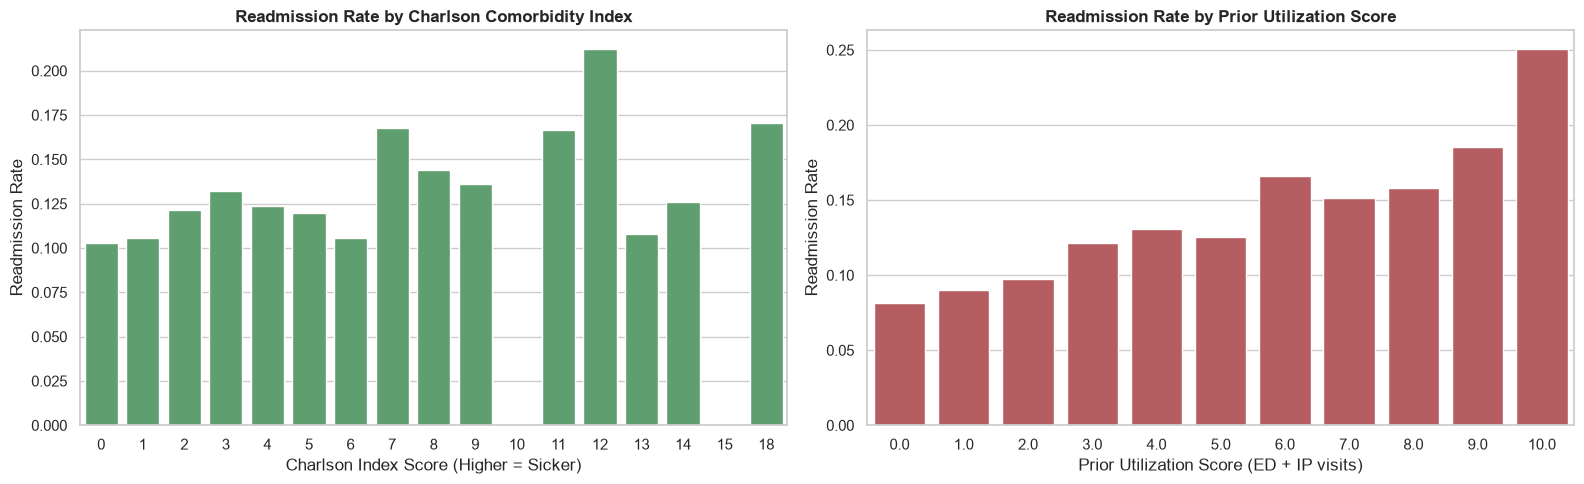

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Charlson Comorbidity Index
sns.barplot(data=df, x="charlson_index", y="readmitted_30d", ax=axes[0], 
            color="#55A868", errorbar=None)
axes[0].set_title("Readmission Rate by Charlson Comorbidity Index", fontweight="bold")
axes[0].set_ylabel("Readmission Rate")
axes[0].set_xlabel("Charlson Index Score (Higher = Sicker)")

# 2. Prior Utilization Score
temp_df = df.copy()
temp_df["prior_util_capped"] = temp_df["prior_utilization_score"].clip(upper=10)
sns.barplot(data=temp_df, x="prior_util_capped", y="readmitted_30d", ax=axes[1], 
            color="#C44E52", errorbar=None)
axes[1].set_title("Readmission Rate by Prior Utilization Score", fontweight="bold")
axes[1].set_ylabel("Readmission Rate")
axes[1].set_xlabel("Prior Utilization Score (ED + IP visits)")

plt.tight_layout()
plt.show()

Conclusion

In [8]:
# Calculate actual risk factor increase
low_risk = df[df["prior_utilization_score"] == 0]["readmitted_30d"].mean()
high_risk = df[df["prior_utilization_score"] > 5]["readmitted_30d"].mean()

print(f"Readmission rate for patients with NO prior visits: {low_risk:.1%}")
print(f"Readmission rate for patients with >5 prior visits: {high_risk:.1%}")
print(f"Relative risk increase: {high_risk / low_risk:.1f}x")

Readmission rate for patients with NO prior visits: 8.2%
Readmission rate for patients with >5 prior visits: 19.9%
Relative risk increase: 2.4x
